In [51]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aliyatamang/renttherunway-final-data/renttherunway_final_data.json


# OwnableFit
## Dataset Analysis and Dress Size Code Prediction

This notebook investigates the RentTheRunway dataset for an adult women’s
dress-size recommendation prototype. It documents data preparation,
measurement quality, exploratory analysis, statistical baselines,
model development and final evaluation.

The prediction target is the dataset size code from observations where
customers reported that the dress fitted. These codes are not verified
US/EU labels, and a reported fitting size is not necessarily the only
appropriate size.

Customers are separated across development and test partitions.
Model selection uses an internal validation partition, and the selected
pipeline is refitted on development data before final test evaluation.

The notebook compares machine learning with global and item-specific
majority baselines. A compatible traditional size-chart baseline has not
been established, so the contract’s chart-comparison requirement remains
unresolved. Actual return reduction and environmental savings are not measured.

## Dataset Source and Licence

Source: Rishabh Misra, Clothing Fit Dataset for Size Recommendation.
https://www.kaggle.com/datasets/rmisra/clothing-fit-dataset-for-size-recommendation

Licence: Creative Commons Attribution 4.0 International (CC BY 4.0).
https://creativecommons.org/licenses/by/4.0/

Licence checked on the original uploader’s Kaggle page on 20 October 2026.

Research reference:
Misra, R., Wan, M. and McAuley, J. (2018).
Decomposing fit semantics for product size recommendation in metric spaces.
Proceedings of the 12th ACM Conference on Recommender Systems,
pp. 422–426. https://doi.org/10.1145/3240323.3240398

Changes made in this notebook:
Selected explicit dress records, removed exact duplicates, selected records
with reported age at least 18, and derived metric height and weight columns.
The original input file remains unchanged.

## 1. Load the Original Dataset

In [52]:
from pathlib import Path
import hashlib
import pandas as pd

# Locate the dataset without relying on a particular Kaggle folder name.
matching_files = [
    path
    for path in Path("/kaggle/input").rglob("*.json")
    if "renttherunway" in path.name.lower()
]

if len(matching_files) != 1:
    raise ValueError(
        f"Expected one RentTheRunway JSON file, found {len(matching_files)}. "
        "Check the attached notebook inputs."
    )

dataset_path = matching_files[0]

# Record a fingerprint so the exact input file can be identified later.
file_hash = hashlib.sha256()
with dataset_path.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        file_hash.update(chunk)

# Each line contains one JSON object.
# Keep raw_df unchanged; preparation uses separate DataFrames.
raw_df = pd.read_json(dataset_path, lines=True)

required_columns = {
    "category", "fit", "size", "age", "height",
    "weight", "bust size", "user_id", "item_id"
}

missing_columns = required_columns.difference(raw_df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

print("Input file:", dataset_path.name)
print("SHA-256:", file_hash.hexdigest())
print("Original records:", len(raw_df))
print("Columns:", raw_df.columns.tolist())

Input file: renttherunway_final_data.json
SHA-256: 015dd071b6752f44c515ce235242753cce1043d40c2c6e965b24ae768734e7d6
Original records: 192544
Columns: ['fit', 'user_id', 'bust size', 'item_id', 'weight', 'rating', 'rented for', 'review_text', 'body type', 'review_summary', 'category', 'height', 'size', 'age', 'review_date']


## 2. Select Dresses and Remove Exact Duplicates

In [53]:
# Use the explicit category label to keep the garment scope reproducible.
# We do not combine dresses with gowns, rompers or other categories.
dress_records = raw_df.loc[raw_df["category"].eq("dress")].copy()

# An exact duplicate must match across every original column.
# Different reviews from the same customer are not automatically duplicates.
duplicate_count = int(dress_records.duplicated().sum())

dresses_df = dress_records.drop_duplicates().copy()

preparation_counts = [
    {"stage": "Original dataset", "records": len(raw_df)},
    {"stage": "Explicit dresses", "records": len(dress_records)},
    {"stage": "Dresses after exact deduplication", "records": len(dresses_df)}
]

print("Exact duplicate dress records removed:", duplicate_count)
display(pd.DataFrame(preparation_counts))

Exact duplicate dress records removed: 132


,stage,records
0,Original dataset,192544
1,Explicit dresses,92884
2,Dresses after exact deduplication,92752


## 3. Identify the Recorded Adult Cohort

In [54]:
# Preserve the supplied age and create a separate numeric version.
# Invalid values become missing rather than being guessed.
dresses_df["age_years"] = pd.to_numeric(
    dresses_df["age"], errors="coerce"
)

age = dresses_df["age_years"]

# Recorded age is self-reported information, not verified adulthood.
adult_mask = age.ge(18)

age_audit = pd.DataFrame({
    "group": [
        "Recorded age at least 18",
        "Recorded age below 18",
        "Missing or non-numeric age"
    ],
    "records": [
        int(adult_mask.sum()),
        int(age.lt(18).sum()),
        int(age.isna().sum())
    ]
})

adult_df = dresses_df.loc[adult_mask].copy()

# Unusually high ages remain in the working data.
# The contract does not impose an arbitrary upper age limit.
# Inspect the distribution before deciding whether values are erroneous.
preparation_counts.append({
    "stage": "Recorded age at least 18",
    "records": len(adult_df)
})

display(age_audit)
print("Recorded adult cohort:", len(adult_df))
print("\nHighest recorded ages and their frequencies:")
display(adult_df["age_years"].value_counts().sort_index().tail(15))

,group,records
0,Recorded age at least 18,92221
1,Recorded age below 18,133
2,Missing or non-numeric age,398


Recorded adult cohort: 92221

Highest recorded ages and their frequencies:


age_years
70.0     15
71.0      4
72.0      3
73.0      3
74.0      2
75.0      4
76.0      4
78.0      1
87.0      2
91.0      9
92.0      1
106.0     1
109.0     1
116.0    10
117.0    21
Name: count, dtype: int64

## 4. Convert Height and Weight to Metric Units

In [55]:
# Parse only the documented feet/inches height format.
# Values that do not match are left missing for review.
height_text = adult_df["height"].astype("string").str.strip()

height_parts = height_text.str.extract(
    r"""^(?P<feet>\d+)\s*'\s*(?P<inches>\d+(?:\.\d+)?)\s*"?$"""
)

feet = pd.to_numeric(height_parts["feet"], errors="coerce")
inches = pd.to_numeric(height_parts["inches"], errors="coerce")

valid_height_format = feet.notna() & inches.ge(0) & inches.lt(12)

# One foot contains 12 inches; one inch is exactly 2.54 cm.
adult_df["height_cm"] = (
    (feet * 12 + inches) * 2.54
).where(valid_height_format)

# Parse the supplied pounds format without silently assuming other units.
weight_text = adult_df["weight"].astype("string").str.strip()

weight_lb = pd.to_numeric(
    weight_text.str.extract(
        r"(?i)^(\d+(?:\.\d+)?)\s*lbs?$",
        expand=False
    ),
    errors="coerce"
)

# One pound is exactly 0.45359237 kg.
adult_df["weight_kg"] = (weight_lb * 0.45359237).where(
    weight_lb.gt(0)
)

# Separate supplied missing values from values that failed conversion.
conversion_audit = pd.DataFrame([
    {
        "field": "height",
        "original_missing": int(adult_df["height"].isna().sum()),
        "present_but_unconverted": int(
            (adult_df["height"].notna()
             & adult_df["height_cm"].isna()).sum()
        ),
        "usable_metric_values": int(adult_df["height_cm"].notna().sum())
    },
    {
        "field": "weight",
        "original_missing": int(adult_df["weight"].isna().sum()),
        "present_but_unconverted": int(
            (adult_df["weight"].notna()
             & adult_df["weight_kg"].isna()).sum()
        ),
        "usable_metric_values": int(adult_df["weight_kg"].notna().sum())
    }
])

display(conversion_audit)
display(adult_df[["height_cm", "weight_kg", "age_years"]].describe())

,field,original_missing,present_but_unconverted,usable_metric_values
0,height,307,0,91914
1,weight,14244,0,77977


,height_cm,weight_kg,age_years
count,91914.0,77977.0,92221.000000
mean,165.675075,62.317072,33.834485
std,6.778818,9.850131,7.695599
min,137.16,22.679619,18.000000
25%,160.02,56.245454,29.000000
50%,165.1,61.23497,32.000000
75%,170.18,67.585263,37.000000
max,193.04,136.077711,117.000000


## 5. Audit Fit Labels and Size Codes

In [56]:
# Normalise spelling and whitespace while retaining the original columns.
adult_df["fit_label"] = (
    adult_df["fit"].astype("string").str.strip().str.lower()
)

# These are dataset codes, not verified US or EU size labels.
adult_df["size_code"] = pd.to_numeric(
    adult_df["size"], errors="coerce"
)

valid_fit_labels = {"small", "fit", "large"}

adult_df["fit_label_valid"] = adult_df["fit_label"].isin(
    valid_fit_labels
)

# Integer-valued codes are expected; do not round unexpected values.
adult_df["size_code_valid"] = (
    adult_df["size_code"].notna()
    & adult_df["size_code"].mod(1).eq(0)
)

fit_counts = adult_df["fit_label"].value_counts(dropna=False)

fit_summary = fit_counts.rename_axis("fit_label").reset_index(
    name="records"
)
fit_summary["percentage"] = (
    100 * fit_summary["records"] / len(adult_df)
).round(2)

display(fit_summary)

print("Unexpected or missing fit labels:",
      int((~adult_df["fit_label_valid"]).sum()))
print("Invalid or missing size codes:",
      int((~adult_df["size_code_valid"]).sum()))

print("\nObserved size codes:")
print(sorted(adult_df["size_code"].dropna().unique().tolist()))

# A small/large observation does not reveal the correct replacement size.
# Do not create targets by adding or subtracting a size code.

,fit_label,records,percentage
0,fit,66080,71.65
1,small,13579,14.72
2,large,12562,13.62


Unexpected or missing fit labels: 0
Invalid or missing size codes: 0

Observed size codes:
[0, 1, 2, 3, 4, 5, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17, 19, 20, 21, 23, 24, 25, 26, 28, 29, 32, 34, 35, 39, 42, 45, 46, 48, 50, 51, 54, 57]


## 6. Check Missing Data and Supported Inputs

In [57]:
# Bra size is retained as a reported category.
# It is not converted into a measured chest circumference.
audit_columns = [
    "height_cm", "weight_kg", "bust size",
    "body type", "age_years", "size_code", "fit_label"
]

missing_summary = (
    adult_df[audit_columns]
    .isna()
    .sum()
    .rename("missing_records")
    .to_frame()
)

missing_summary["missing_percentage"] = (
    100 * missing_summary["missing_records"] / len(adult_df)
).round(2)

display(missing_summary)

# No missing-value imputation is performed at this stage.
# Later, any learned imputation must be fitted on training data only.
print(
    "The released data does not establish measured waist/hip inputs "
    "or a verified size-chart mapping."
)

,missing_records,missing_percentage
height_cm,307,0.33
weight_kg,14244,15.45
bust size,8842,9.59
body type,6846,7.42
age_years,0,0.00
size_code,0,0.00
fit_label,0,0.00


The released data does not establish measured waist/hip inputs or a verified size-chart mapping.


## 7. Count Potential Fit-Supported Targets

In [58]:
# This subset supports a possible size-code prediction experiment.
# The target means 'reported as fitting', not 'only correct size'.
fit_supported_mask = (
    adult_df["fit_label"].eq("fit")
    & adult_df["size_code_valid"]
)

fit_supported_df = adult_df.loc[fit_supported_mask].copy()

coverage_summary = pd.DataFrame({
    "check": [
        "Adult dress observations",
        "Fit-supported observations with valid size codes",
        "Fit-supported observations with height and weight"
    ],
    "records": [
        len(adult_df),
        len(fit_supported_df),
        int(
            fit_supported_df[["height_cm", "weight_kg"]]
            .notna()
            .all(axis=1)
            .sum()
        )
    ]
})

display(coverage_summary)

# Inspect rare targets before deciding which sizes can be evaluated.
size_coverage = (
    fit_supported_df.groupby("size_code")
    .agg(
        records=("size_code", "size"),
        customers=("user_id", "nunique"),
        items=("item_id", "nunique")
    )
    .reset_index()
    .sort_values("size_code")
)

display(size_coverage)

# Do not discard small/large observations from adult_df.
# They remain available for a possible separate fit-prediction experiment.

,check,records
0,Adult dress observations,92221
1,Fit-supported observations with valid size codes,66080
2,Fit-supported observations with height and weight,55569


,size_code,records,customers,items
0,0,18,18,7
1,1,5054,3919,1073
2,2,24,24,7
3,3,22,22,12
4,4,10612,8139,1844
5,5,39,39,10
6,7,25,25,13
7,8,15461,11614,2020
8,9,45,45,12
9,11,14,14,7


## 8. Check Customer and Item Coverage

In [59]:
# Repeated customers create a risk of overly optimistic evaluation
# if their observations appear in both training and test sets.
customer_counts = adult_df.groupby("user_id").size()
item_counts = adult_df.groupby("item_id").size()

coverage = pd.DataFrame({
    "measure": [
        "Unique customers",
        "Customers with multiple observations",
        "Unique items",
        "Items with only one observation"
    ],
    "count": [
        adult_df["user_id"].nunique(),
        int(customer_counts.gt(1).sum()),
        adult_df["item_id"].nunique(),
        int(item_counts.eq(1).sum())
    ]
})

display(coverage)

# Do not split or train yet.
# The eventual plan will use customer groups to avoid customer overlap.
# The contract's 70/30 allocation must account for unequal group sizes.

,measure,count
0,Unique customers,57916
1,Customers with multiple observations,15611
2,Unique items,2614
3,Items with only one observation,121


## 9. Record the Feasibility Decision

In [60]:
# Keep unresolved questions visible instead of treating them as solved.
feasibility_status = pd.DataFrame([
    {
        "requirement": "Explicit dress records",
        "status": "Confirmed",
        "evidence": f"{len(dresses_df):,} after exact deduplication"
    },
    {
        "requirement": "Recorded adult cohort",
        "status": "Confirmed with self-report limitation",
        "evidence": f"{len(adult_df):,} records with recorded age >= 18"
    },
    {
        "requirement": "Fit-supported size targets",
        "status": "Available with limitations",
        "evidence": f"{len(fit_supported_df):,} reported-fit observations"
    },
    {
        "requirement": "Size-code interpretation",
        "status": "Partially resolved",
        "evidence": "Ordered standardised codes; retail-label mapping unverified"
    },
    {
        "requirement": "Dataset usage conditions",
        "status": "Unresolved",
        "evidence": "Record the original uploader's explicit licence"
    },
    {
        "requirement": "Traditional size-chart baseline",
        "status": "Unresolved",
        "evidence": "Needs compatible measurements, labels and garment coverage"
    }
])

display(feasibility_status)

print(
    "Preparation completed. No model has been trained. "
    "Resolve the licence and chart baseline before model development."
)

,requirement,status,evidence
0,Explicit dress records,Confirmed,"92,752 after exact deduplication"
1,Recorded adult cohort,Confirmed with self-report limitation,"92,221 records with recorded age >= 18"
2,Fit-supported size targets,Available with limitations,"66,080 reported-fit observations"
3,Size-code interpretation,Partially resolved,Ordered standardised codes; retail-label mappi...
4,Dataset usage conditions,Unresolved,Record the original uploader's explicit licence
5,Traditional size-chart baseline,Unresolved,"Needs compatible measurements, labels and garm..."


Preparation completed. No model has been trained. Resolve the licence and chart baseline before model development.


In [61]:
# Show the full text in the feasibility table.
with pd.option_context("display.max_colwidth", None):
    display(feasibility_status)

,requirement,status,evidence
0,Explicit dress records,Confirmed,"92,752 after exact deduplication"
1,Recorded adult cohort,Confirmed with self-report limitation,"92,221 records with recorded age >= 18"
2,Fit-supported size targets,Available with limitations,"66,080 reported-fit observations"
3,Size-code interpretation,Partially resolved,Ordered standardised codes; retail-label mapping unverified
4,Dataset usage conditions,Unresolved,Record the original uploader's explicit licence
5,Traditional size-chart baseline,Unresolved,"Needs compatible measurements, labels and garment coverage"


In [62]:
# Record the source licence reported from the original uploader's page.
licence_row = feasibility_status["requirement"].eq(
    "Dataset usage conditions"
)

feasibility_status.loc[licence_row, "status"] = (
    "Source licence checked"
)
feasibility_status.loc[licence_row, "evidence"] = (
    "Original Kaggle page lists CC BY 4.0; "
    "credit source, link licence and document changes."
)

with pd.option_context("display.max_colwidth", None):
    display(feasibility_status)

,requirement,status,evidence
0,Explicit dress records,Confirmed,"92,752 after exact deduplication"
1,Recorded adult cohort,Confirmed with self-report limitation,"92,221 records with recorded age >= 18"
2,Fit-supported size targets,Available with limitations,"66,080 reported-fit observations"
3,Size-code interpretation,Partially resolved,Ordered standardised codes; retail-label mapping unverified
4,Dataset usage conditions,Source licence checked,"Original Kaggle page lists CC BY 4.0; credit source, link licence and document changes."
5,Traditional size-chart baseline,Unresolved,"Needs compatible measurements, labels and garment coverage"


## 10. Explore Fit-Supported Size Coverage

This section examines records where customers reported that the dress fitted.
Size values remain dataset codes. These observations do not establish a unique
correct size or demonstrate a reduction in returns.

In [63]:
# Examine the potential target data before choosing model inputs.
# fit_supported_df was created in Cell 7.

print("Fit-supported observations:", len(fit_supported_df))
print("Unique customers:", fit_supported_df["user_id"].nunique())
print("Unique dress items:", fit_supported_df["item_id"].nunique())

# Count observations for each size code.
# Rare sizes may be difficult to train on and evaluate reliably.
size_counts = (
    fit_supported_df["size_code"]
    .value_counts()
    .sort_index()
    .rename_axis("size_code")
    .reset_index(name="records")
)

display(size_counts)

# Check how many observations have both metric measurements.
# This is a coverage check, not a decision to delete incomplete records.
measurement_coverage = (
    fit_supported_df[["height_cm", "weight_kg"]]
    .notna()
    .all(axis=1)
)

print(
    "Observations with both height and weight:",
    int(measurement_coverage.sum())
)
print(
    "Observations missing either measurement:",
    int((~measurement_coverage).sum())
)

Fit-supported observations: 66080
Unique customers: 45120
Unique dress items: 2531


,size_code,records
0,0,18
1,1,5054
2,2,24
3,3,22
4,4,10612
5,5,39
6,7,25
7,8,15461
8,9,45
9,11,14


Observations with both height and weight: 55569
Observations missing either measurement: 10511


## 11. Check Measurement Quality

Inspect measurement ranges and missing-data patterns before deciding how
to handle incomplete or unusual observations. No records are removed here.

In [64]:
# Summarise the available measurements.
# Extreme values require review; they are not automatically errors.
measurement_columns = ["height_cm", "weight_kg", "age_years"]

display(
    fit_supported_df[measurement_columns].describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    ).round(2)
)

# Identify which measurements are missing.
# This helps us assess whether deleting incomplete rows could bias the sample.
height_present = fit_supported_df["height_cm"].notna()
weight_present = fit_supported_df["weight_kg"].notna()

missing_patterns = pd.DataFrame({
    "measurement_availability": [
        "Both height and weight",
        "Height only",
        "Weight only",
        "Neither height nor weight"
    ],
    "records": [
        int((height_present & weight_present).sum()),
        int((height_present & ~weight_present).sum()),
        int((~height_present & weight_present).sum()),
        int((~height_present & ~weight_present).sum())
    ]
})

display(missing_patterns)

# Compare measurement completeness across size codes.
# A low coverage rate may disproportionately affect a particular size.
coverage_by_size = (
    fit_supported_df
    .assign(has_both_measurements=height_present & weight_present)
    .groupby("size_code")
    .agg(
        records=("size_code", "size"),
        complete_measurements=("has_both_measurements", "sum")
    )
)

coverage_by_size["complete_percentage"] = (
    100 * coverage_by_size["complete_measurements"]
    / coverage_by_size["records"]
).round(1)

display(coverage_by_size)

,height_cm,weight_kg,age_years
count,65863.0,55710.0,66080.0
mean,165.72,62.31,33.9
std,6.79,9.87,7.7
min,137.16,22.68,18.0
1%,152.4,45.36,21.0
5%,154.94,49.9,25.0
50%,165.1,61.23,32.0
95%,177.8,80.74,49.0
99%,182.88,95.25,58.0
max,193.04,136.08,117.0


,measurement_availability,records
0,Both height and weight,55569
1,Height only,10294
2,Weight only,141
3,Neither height nor weight,76


,records,complete_measurements,complete_percentage
size_code,,,
0,18,15,83.3
1,5054,4615,91.3
2,24,21,87.5
3,22,20,90.9
4,10612,9707,91.5
5,39,32,82.1
7,25,22,88.0
8,15461,13734,88.8
9,45,41,91.1


## 12. Review Unusual Measurement Values

Inspect the original values behind measurement extremes.
These checks do not remove records or establish that a value is incorrect.

In [65]:
# Inspect the lowest and highest recorded weights.
# Original values help distinguish conversion issues from source-data issues.
review_columns = [
    "height", "height_cm",
    "weight", "weight_kg",
    "age_years", "size_code"
]

print("Ten lowest recorded weights:")
display(
    fit_supported_df
    .nsmallest(10, "weight_kg")[review_columns]
    .reset_index(drop=True)
)

print("Ten highest recorded weights:")
display(
    fit_supported_df
    .nlargest(10, "weight_kg")[review_columns]
    .reset_index(drop=True)
)

# Inspect the oldest recorded ages without imposing an exclusion threshold.
print("Ten highest recorded ages:")
display(
    fit_supported_df
    .nlargest(10, "age_years")[review_columns]
    .reset_index(drop=True)
)

Ten lowest recorded weights:


,height,height_cm,weight,weight_kg,age_years,size_code
0,"5' 6""",167.64,50lbs,22.679619,29.0,12
1,"5' 6""",167.64,50lbs,22.679619,29.0,16
2,"6' 0""",182.88,79lbs,35.833797,22.0,20
3,"5' 0""",152.4,85lbs,38.555351,28.0,1
4,"5' 3""",160.02,88lbs,39.916129,33.0,4
5,"5' 3""",160.02,89lbs,40.369721,19.0,1
6,"5' 2""",157.48,89lbs,40.369721,29.0,1
7,"5' 1""",154.94,90lbs,40.823313,31.0,1
8,"5' 1""",154.94,90lbs,40.823313,30.0,2
9,"4' 10""",147.32,90lbs,40.823313,19.0,4


Ten highest recorded weights:


,height,height_cm,weight,weight_kg,age_years,size_code
0,"5' 6""",167.64,300lbs,136.077711,36.0,57
1,"5' 5""",165.1,300lbs,136.077711,37.0,57
2,"5' 6""",167.64,290lbs,131.541787,29.0,57
3,"5' 3""",160.02,290lbs,131.541787,31.0,57
4,"5' 7""",170.18,285lbs,129.273825,30.0,39
5,"5' 10""",177.8,285lbs,129.273825,33.0,51
6,"5' 7""",170.18,285lbs,129.273825,19.0,24
7,"5' 7""",170.18,285lbs,129.273825,30.0,45
8,"5' 2""",157.48,285lbs,129.273825,34.0,45
9,"5' 7""",170.18,280lbs,127.005864,32.0,57


Ten highest recorded ages:


,height,height_cm,weight,weight_kg,age_years,size_code
0,"5' 2""",157.48,NaN,<NA>,117.0,16
1,"5' 5""",165.1,115lbs,52.163123,117.0,8
2,"5' 1""",154.94,NaN,<NA>,117.0,16
3,"5' 0""",152.4,105lbs,47.627199,117.0,1
4,"5' 1""",154.94,NaN,<NA>,117.0,16
5,"5' 5""",165.1,115lbs,52.163123,117.0,8
6,"5' 0""",152.4,105lbs,47.627199,117.0,4
7,"5' 1""",154.94,NaN,<NA>,117.0,12
8,"5' 5""",165.1,115lbs,52.163123,117.0,8
9,"5' 0""",152.4,105lbs,47.627199,117.0,4


## 13. Define the Initial Modelling Table

The target is the dataset size code for a dress reported as fitting.
Initial inputs are height, weight and reported bra size.
Missing measurements and rare size codes are retained.

In [66]:
# Create a separate table without changing the prepared source data.
# Only include records with a reported fit and a valid size code.
model_df = fit_supported_df[
    ["user_id", "item_id", "height_cm",
     "weight_kg", "bust size", "size_code"]
].copy()

model_df = model_df.rename(columns={"bust size": "bra_size"})

# Treat reported bra size as a category, not a chest measurement.
model_df["bra_size"] = (
    model_df["bra_size"]
    .astype("string")
    .str.strip()
    .str.lower()
)
model_df["bra_size"] = model_df["bra_size"].replace("", pd.NA)

# These codes identify target classes; they are not US/EU labels.
model_df["size_code"] = model_df["size_code"].astype("int64")

# IDs are retained for grouping and coverage checks.
# They are not initial model input features.
feature_columns = ["height_cm", "weight_kg", "bra_size"]
target_column = "size_code"

# Missing customer IDs must be resolved before customer-grouped splitting.
if model_df["user_id"].isna().any():
    raise ValueError(
        "Missing customer IDs found. Review before splitting."
    )

print("Modelling observations:", len(model_df))
print("Input features:", feature_columns)
print("Target:", target_column)
print("Number of target classes:", model_df[target_column].nunique())

print("\nMissing input values:")
display(model_df[feature_columns].isna().sum().to_frame("records"))

# No imputation, splitting or training is performed here.

Modelling observations: 66080
Input features: ['height_cm', 'weight_kg', 'bra_size']
Target: size_code
Number of target classes: 37

Missing input values:


,records
height_cm,217
weight_kg,10370
bra_size,6396


## 14. Create a Customer Grouped Holdout

Allocate approximately 70% of customers to development and 30% to testing.
Keep every customer's observations in one partition to prevent customer overlap.
The test partition will remain unused during model selection.

In [67]:
from sklearn.model_selection import GroupShuffleSplit

# Use a fixed seed so the split can be reproduced.
splitter = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=42
)

development_positions, test_positions = next(
    splitter.split(model_df, groups=model_df["user_id"])
)

development_df = model_df.iloc[development_positions].copy()
test_df = model_df.iloc[test_positions].copy()

# Verify that no customer appears in both partitions.
development_customers = set(development_df["user_id"])
test_customers = set(test_df["user_id"])

assert development_customers.isdisjoint(test_customers)
assert len(development_df) + len(test_df) == len(model_df)

# Report allocation only; do not evaluate or tune using test outcomes.
split_summary = pd.DataFrame({
    "partition": ["Development", "Held-out test"],
    "records": [len(development_df), len(test_df)],
    "customers": [
        len(development_customers),
        len(test_customers)
    ]
})

split_summary["record_percentage"] = (
    100 * split_summary["records"] / len(model_df)
).round(2)

display(split_summary)
print("Customer overlap: 0")
print("No model has been trained.")

# Preprocessing and model selection will use development_df only.
# We will create an internal validation split within it next.

,partition,records,customers,record_percentage
0,Development,46477,31583,70.33
1,Held-out test,19603,13537,29.67


Customer overlap: 0
No model has been trained.


## 15. Create Training and Validation Partitions

Split the development data by customer.
Training data will fit preprocessing and models.
Validation data will support model selection.
The existing test partition remains untouched.

In [68]:
# Allocate 20% of development customers to validation.
# This does not change the existing held-out test partition.
validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_positions, validation_positions = next(
    validation_splitter.split(
        development_df,
        groups=development_df["user_id"]
    )
)

train_df = development_df.iloc[train_positions].copy()
validation_df = development_df.iloc[validation_positions].copy()

# Verify that all three customer groups are separate.
train_customers = set(train_df["user_id"])
validation_customers = set(validation_df["user_id"])

assert train_customers.isdisjoint(validation_customers)
assert train_customers.isdisjoint(test_customers)
assert validation_customers.isdisjoint(test_customers)
assert len(train_df) + len(validation_df) == len(development_df)

summary = pd.DataFrame({
    "partition": ["Training", "Validation"],
    "records": [len(train_df), len(validation_df)],
    "customers": [
        len(train_customers),
        len(validation_customers)
    ]
})

display(summary)

# Some rare size codes may be absent from training.
# Report this limitation rather than changing the split to hide it.
validation_only_codes = sorted(
    set(validation_df["size_code"]) - set(train_df["size_code"])
)

print("Validation size codes absent from training:", validation_only_codes)
print("Customer overlap across all partitions: 0")
print("No model has been trained.")

,partition,records,customers
0,Training,37305,25266
1,Validation,9172,6317


Validation size codes absent from training: []
Customer overlap across all partitions: 0
No model has been trained.


## 16. Define Preprocessing

Numeric inputs use median imputation and standardisation.
Reported bra size is treated as a category.
All learned preprocessing will be fitted on training data only.

In [69]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["height_cm", "weight_kg"]
categorical_features = ["bra_size"]

# Convert pandas missing values into a consistent format for scikit-learn.
# This helper does not learn anything from the data.
def prepare_inputs(frame):
    inputs = frame[feature_columns].copy()

    for column in numeric_features:
        inputs[column] = pd.to_numeric(
            inputs[column], errors="coerce"
        ).astype("float64")

    for column in categorical_features:
        inputs[column] = inputs[column].astype(object)
        inputs[column] = inputs[column].where(
            pd.notna(inputs[column]), np.nan
        )

    return inputs


X_train = prepare_inputs(train_df)
y_train = train_df[target_column].copy()

X_validation = prepare_inputs(validation_df)
y_validation = validation_df[target_column].copy()

# Missingness indicators let a future model distinguish recorded values
# from values filled using the training median.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_validation.shape)
print("Preprocessing defined but not fitted.")
print("Test data remains untouched.")

Training input shape: (37305, 3)
Validation input shape: (9172, 3)
Preprocessing defined but not fitted.
Test data remains untouched.


## 17. Evaluate a Majority Class Baseline

Always predict the most frequent training size code.
Evaluate on validation data only.
This statistical baseline does not represent a traditional size chart.

In [70]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# Learn only which target class is most frequent in training.
# This baseline does not use body measurements or preprocessing.
majority_baseline = DummyClassifier(strategy="most_frequent")
majority_baseline.fit(X_train, y_train)

validation_predictions = majority_baseline.predict(X_validation)

# Use a fixed class list so later models are compared consistently.
# Macro metrics give each size class equal importance.
evaluation_labels = sorted(y_train.unique())

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_validation,
        validation_predictions,
        labels=evaluation_labels,
        average="macro",
        zero_division=0
    )
)

baseline_results = pd.DataFrame([{
    "method": "Majority class",
    "validation_accuracy": accuracy_score(
        y_validation, validation_predictions
    ),
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1
}])

print("Always predicts dataset size code:",
      int(validation_predictions[0]))

display(baseline_results.round(4))
print("Test data remains untouched.")

Always predicts dataset size code: 8


,method,validation_accuracy,macro_precision,macro_recall,macro_f1
0,Majority class,0.229,0.0062,0.027,0.0101


Test data remains untouched.


## 18. Train and Validate Logistic Regression

Predict reported-fit size codes using height, weight and reported bra size.
Fit preprocessing on training data only and evaluate on validation data.

In [71]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# A pipeline fits preprocessing using training data only.
# Validation inputs receive the same transformations without refitting.
logistic_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        max_iter=2000
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_validation)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_validation,
        logistic_predictions,
        labels=evaluation_labels,
        average="macro",
        zero_division=0
    )
)

logistic_results = pd.DataFrame([{
    "method": "Logistic regression",
    "validation_accuracy": accuracy_score(
        y_validation, logistic_predictions
    ),
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1
}])

comparison_results = pd.concat(
    [baseline_results, logistic_results],
    ignore_index=True
)

display(comparison_results.round(4))

# Express the improvement in percentage points, not relative percent.
accuracy_gain = 100 * (
    logistic_results.loc[0, "validation_accuracy"]
    - baseline_results.loc[0, "validation_accuracy"]
)

print(
    f"Accuracy improvement over majority baseline: "
    f"{accuracy_gain:.2f} percentage points"
)
print("Test data remains untouched.")

,method,validation_accuracy,macro_precision,macro_recall,macro_f1
0,Majority class,0.2290,0.0062,0.0270,0.0101
1,Logistic regression,0.3969,0.1428,0.0975,0.1042


Accuracy improvement over majority baseline: 16.79 percentage points
Test data remains untouched.


## 19. Examine Performance by Size Code

Inspect precision, recall and F1 for each size code.
Compare training and validation accuracy to check for a large performance gap.

In [72]:
from sklearn.metrics import classification_report

# Compare training and validation performance.
# A large gap could indicate overfitting; a small gap does not prove
# that the model has captured all useful relationships.
training_predictions = logistic_model.predict(X_train)

print(
    "Training accuracy:",
    round(accuracy_score(y_train, training_predictions), 4)
)
print(
    "Validation accuracy:",
    round(accuracy_score(y_validation, logistic_predictions), 4)
)

# Show performance separately for each size code.
# Support is the number of validation observations for that code.
report = classification_report(
    y_validation,
    logistic_predictions,
    labels=evaluation_labels,
    output_dict=True,
    zero_division=0
)

per_size_results = pd.DataFrame([
    {
        "size_code": code,
        "precision": report[str(code)]["precision"],
        "recall": report[str(code)]["recall"],
        "f1": report[str(code)]["f1-score"],
        "validation_records": int(report[str(code)]["support"]),
        "predicted_records": int((logistic_predictions == code).sum())
    }
    for code in evaluation_labels
])

display(per_size_results.round(4))

print("Test data remains untouched.")

Training accuracy: 0.3984
Validation accuracy: 0.3969


,size_code,precision,recall,f1,validation_records,predicted_records
0,0,0.0000,0.0000,0.0000,3,0
1,1,0.6222,0.3308,0.4320,662,352
2,2,0.0000,0.0000,0.0000,5,0
3,3,0.0000,0.0000,0.0000,3,0
4,4,0.4910,0.4801,0.4855,1481,1448
5,5,0.0000,0.0000,0.0000,7,0
6,7,0.0000,0.0000,0.0000,4,0
7,8,0.4027,0.6910,0.5089,2100,3603
8,9,0.0000,0.0000,0.0000,4,0
9,11,0.0000,0.0000,0.0000,5,0


Test data remains untouched.


## 20. Evaluate Class Balanced Logistic Regression

Give less frequent training classes greater weight.
Compare accuracy and macro F1 on the same validation partition.
This experiment tests whether class imbalance contributes to poor size coverage.

In [73]:
# Keep preprocessing and model settings unchanged except class weighting.
# This makes the comparison easier to interpret.
balanced_logistic_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        class_weight="balanced",
        max_iter=2000
    ))
])

balanced_logistic_model.fit(X_train, y_train)

balanced_predictions = balanced_logistic_model.predict(X_validation)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_validation,
    balanced_predictions,
    labels=evaluation_labels,
    average="macro",
    zero_division=0
)

balanced_results = pd.DataFrame([{
    "method": "Balanced logistic regression",
    "validation_accuracy": accuracy_score(
        y_validation, balanced_predictions
    ),
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": f1
}])

# Rebuild the comparison so rerunning this cell does not duplicate rows.
comparison_results = pd.concat(
    [baseline_results, logistic_results, balanced_results],
    ignore_index=True
)

display(comparison_results.round(4))
print("Test data remains untouched.")

,method,validation_accuracy,macro_precision,macro_recall,macro_f1
0,Majority class,0.2290,0.0062,0.0270,0.0101
1,Logistic regression,0.3969,0.1428,0.0975,0.1042
2,Balanced logistic regression,0.1212,0.1128,0.1398,0.0721


Test data remains untouched.


## 21. Evaluate a Random Forest

Compare a nonlinear classifier with logistic regression using the same
inputs, preprocessing and validation partition.

In [74]:
from sklearn.ensemble import RandomForestClassifier

# Restrict tree depth and require multiple observations per leaf
# to limit memorisation of small groups.
forest_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_validation)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_validation,
    forest_predictions,
    labels=evaluation_labels,
    average="macro",
    zero_division=0
)

forest_results = pd.DataFrame([{
    "method": "Random forest",
    "validation_accuracy": accuracy_score(
        y_validation, forest_predictions
    ),
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": f1
}])

comparison_results = pd.concat(
    [
        baseline_results,
        logistic_results,
        balanced_results,
        forest_results
    ],
    ignore_index=True
)

display(comparison_results.round(4))

forest_training_predictions = forest_model.predict(X_train)
print(
    "Random forest training accuracy:",
    round(accuracy_score(y_train, forest_training_predictions), 4)
)
print("Test data remains untouched.")

,method,validation_accuracy,macro_precision,macro_recall,macro_f1
0,Majority class,0.2290,0.0062,0.0270,0.0101
1,Logistic regression,0.3969,0.1428,0.0975,0.1042
2,Balanced logistic regression,0.1212,0.1128,0.1398,0.0721
3,Random forest,0.3816,0.0931,0.0721,0.0693


Random forest training accuracy: 0.4354
Test data remains untouched.


## 22. Check Dress Item Coverage

Measure whether validation dresses were observed during training.
This informs whether an item-aware experiment is feasible.
No model is trained and the test partition remains untouched.

In [75]:
# Item IDs identify dresses; they do not reveal brand or physical dimensions.
# Check coverage using training and validation data only.
known_items = set(train_df["item_id"].dropna())

validation_item_seen = (
    validation_df["item_id"].notna()
    & validation_df["item_id"].isin(known_items)
)

item_coverage = pd.DataFrame({
    "validation_group": [
        "Dress item seen in training",
        "Dress item unseen or missing"
    ],
    "records": [
        int(validation_item_seen.sum()),
        int((~validation_item_seen).sum())
    ]
})

item_coverage["percentage"] = (
    100 * item_coverage["records"] / len(validation_df)
).round(2)

display(item_coverage)

# A dress may have several reported-fit sizes across different customers.
# This measures data coverage, not verified stock availability.
training_item_summary = (
    train_df.groupby("item_id")
    .agg(
        observations=("size_code", "size"),
        observed_size_codes=("size_code", "nunique")
    )
)

print("Training dress items:", len(training_item_summary))
print(
    "Training items with at least two observed size codes:",
    int(training_item_summary["observed_size_codes"].ge(2).sum())
)
print("Test data remains untouched.")

,validation_group,records,percentage
0,Dress item seen in training,9119,99.42
1,Dress item unseen or missing,53,0.58


Training dress items: 2434
Training items with at least two observed size codes: 2101
Test data remains untouched.


## 23. Evaluate Item Aware Logistic Regression

Add dress item identity to the existing customer measurements.
Compare against the customer-only model on the same validation records.
Item identity does not provide physical garment measurements or stock availability.

In [76]:
# Build new inputs separately to preserve the earlier experiments.
def prepare_item_inputs(frame):
    inputs = prepare_inputs(frame)

    # Prefix IDs to make their categorical meaning explicit.
    item_text = frame["item_id"].astype("string")
    inputs["dress_item"] = ("item_" + item_text).astype(object)
    inputs["dress_item"] = inputs["dress_item"].where(
        item_text.notna(), np.nan
    )

    return inputs


X_train_item = prepare_item_inputs(train_df)
X_validation_item = prepare_item_inputs(validation_df)

# Reuse the same numeric processing.
# Unknown dress IDs receive no learned item-specific contribution.
item_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), numeric_features),
    (
        "categorical",
        clone(categorical_pipeline),
        ["bra_size", "dress_item"]
    )
])

item_logistic_model = Pipeline([
    ("preprocessing", item_preprocessor),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        max_iter=2000
    ))
])

item_logistic_model.fit(X_train_item, y_train)
item_predictions = item_logistic_model.predict(X_validation_item)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_validation,
    item_predictions,
    labels=evaluation_labels,
    average="macro",
    zero_division=0
)

item_results = pd.DataFrame([{
    "method": "Item-aware logistic regression",
    "validation_accuracy": accuracy_score(y_validation, item_predictions),
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": f1
}])

comparison_results = pd.concat(
    [
        baseline_results,
        logistic_results,
        balanced_results,
        forest_results,
        item_results
    ],
    ignore_index=True
)

display(comparison_results.round(4))

print(
    "Item-aware training accuracy:",
    round(
        accuracy_score(
            y_train,
            item_logistic_model.predict(X_train_item)
        ),
        4
    )
)
print("Test data remains untouched.")

,method,validation_accuracy,macro_precision,macro_recall,macro_f1
0,Majority class,0.2290,0.0062,0.0270,0.0101
1,Logistic regression,0.3969,0.1428,0.0975,0.1042
2,Balanced logistic regression,0.1212,0.1128,0.1398,0.0721
3,Random forest,0.3816,0.0931,0.0721,0.0693
4,Item-aware logistic regression,0.4404,0.2380,0.1767,0.1945


Item-aware training accuracy: 0.5438
Test data remains untouched.


## 24. Evaluate an Item Specific Majority Baseline

Predict each dress's most frequent training size code.
For unseen dresses, use the overall training majority.
This is a statistical baseline, not a traditional size chart.

In [77]:
# Learn a typical code per dress using training observations only.
# In a tie, choose the smallest code for a reproducible result.
item_majority_codes = (
    train_df.groupby("item_id")["size_code"]
    .agg(lambda values: values.mode().min())
)

global_majority_code = int(y_train.mode().min())

# Use the global majority when the dress was not observed in training.
item_baseline_predictions = (
    validation_df["item_id"]
    .map(item_majority_codes)
    .fillna(global_majority_code)
    .astype("int64")
    .to_numpy()
)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_validation,
    item_baseline_predictions,
    labels=evaluation_labels,
    average="macro",
    zero_division=0
)

item_baseline_results = pd.DataFrame([{
    "method": "Item-specific majority",
    "validation_accuracy": accuracy_score(
        y_validation, item_baseline_predictions
    ),
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": f1
}])

comparison_results = pd.concat(
    [
        baseline_results,
        item_baseline_results,
        logistic_results,
        balanced_results,
        forest_results,
        item_results
    ],
    ignore_index=True
)

display(comparison_results.round(4))
print("Test data remains untouched.")

,method,validation_accuracy,macro_precision,macro_recall,macro_f1
0,Majority class,0.2290,0.0062,0.0270,0.0101
1,Item-specific majority,0.2270,0.1301,0.0808,0.0875
2,Logistic regression,0.3969,0.1428,0.0975,0.1042
3,Balanced logistic regression,0.1212,0.1128,0.1398,0.0721
4,Random forest,0.3816,0.0931,0.0721,0.0693
5,Item-aware logistic regression,0.4404,0.2380,0.1767,0.1945


Test data remains untouched.


## 25. Compare Regularisation Strengths

Compare three predefined regularisation settings for item-aware logistic
regression. Use validation accuracy for selection and macro F1 as a tie-breaker.
The held-out test partition remains unused.

In [78]:
# Reuse the existing C=1 model rather than training it again.
regularisation_models = {1.0: item_logistic_model}
regularisation_rows = []

for c_value in [0.1, 1.0, 10.0]:
    if c_value == 1.0:
        candidate = item_logistic_model
    else:
        # Clone creates an unfitted copy of the entire pipeline.
        # Each candidate learns preprocessing from training data only.
        candidate = clone(item_logistic_model)
        candidate.set_params(classifier__C=c_value)
        candidate.fit(X_train_item, y_train)

    regularisation_models[c_value] = candidate
    predictions = candidate.predict(X_validation_item)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_validation,
        predictions,
        labels=evaluation_labels,
        average="macro",
        zero_division=0
    )

    regularisation_rows.append({
        "C": c_value,
        "validation_accuracy": accuracy_score(
            y_validation, predictions
        ),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    })

regularisation_results = pd.DataFrame(regularisation_rows)

# Apply the stated selection rule to unrounded scores.
ranked_results = regularisation_results.sort_values(
    ["validation_accuracy", "macro_f1", "C"],
    ascending=[False, False, True]
)

selected_c = float(ranked_results.iloc[0]["C"])
selected_model = regularisation_models[selected_c]

display(regularisation_results.round(4))
print("Selected C:", selected_c)
print("Test data remains untouched.")

,C,validation_accuracy,macro_precision,macro_recall,macro_f1
0,0.1,0.4258,0.1837,0.0980,0.1062
1,1.0,0.4404,0.2380,0.1767,0.1945
2,10.0,0.4336,0.2473,0.2242,0.2228


Selected C: 1.0
Test data remains untouched.


## 26. Analyse the Selected Model on Validation Data

Inspect common size-code confusions and performance by measurement availability.
These are diagnostic results; the held-out test data remains unused.

In [79]:
# Use the model selected by the predefined validation rule.
selected_predictions = selected_model.predict(X_validation_item)

# Keep diagnostics separate from the original validation table.
validation_diagnostics = validation_df[
    ["height_cm", "weight_kg", "bra_size", "size_code"]
].copy()

validation_diagnostics["predicted_code"] = selected_predictions
validation_diagnostics["correct"] = (
    validation_diagnostics["size_code"]
    == validation_diagnostics["predicted_code"]
)

# Compare observations with all three inputs against those missing any.
# These are descriptive groups, not a causal test of missingness.
validation_diagnostics["input_group"] = np.where(
    validation_diagnostics[
        ["height_cm", "weight_kg", "bra_size"]
    ].notna().all(axis=1),
    "All three inputs recorded",
    "At least one input missing"
)

group_results = (
    validation_diagnostics.groupby("input_group")
    .agg(
        records=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

print("Accuracy by input availability:")
display(group_results.round(4))

# Count the most frequent incorrect predictions.
# Do not interpret code differences as centimetres or US/EU size steps.
errors = validation_diagnostics.loc[
    ~validation_diagnostics["correct"]
]

common_errors = (
    errors.groupby(["size_code", "predicted_code"])
    .size()
    .reset_index(name="records")
    .sort_values(
        ["records", "size_code", "predicted_code"],
        ascending=[False, True, True]
    )
    .head(15)
)

print("Most frequent size-code confusions:")
display(common_errors)

print("Test data remains untouched.")

Accuracy by input availability:


,input_group,records,accuracy
0,All three inputs recorded,7227,0.4717
1,At least one input missing,1945,0.3239


Most frequent size-code confusions:


,size_code,predicted_code,records
18,4,8,551
43,12,8,472
30,8,4,330
61,16,12,311
32,8,12,310
2,1,4,252
52,14,8,193
44,12,16,190
62,16,20,184
83,24,20,172


Test data remains untouched.


## 27. Freeze the Experiment Before Final Testing

### Prediction task
Predict the recorded dataset size code for adult dress observations where
the customer reported that the dress fitted. This is not proof of a unique
correct size or a real-world fit success rate.

### Selected model
Item-aware logistic regression with C = 1.0.
Inputs are height, weight, reported bra size and dress item identity.
Customer identity is used for grouped splitting only.

### Selection rule
Select by validation accuracy, using macro F1 as a tie-breaker.
C = 1.0 achieved 44.04% validation accuracy.
C = 10 achieved higher macro F1 but lower accuracy.

### Evaluation
Keep the existing customer-grouped test partition fixed.
Refit preprocessing and the selected classifier on the full development
partition before evaluating the test partition.
Report accuracy and fixed-label macro precision, recall and F1.
The fixed label list includes development classes absent from a partition;
their zero scores affect the macro averages and must be disclosed.

### Comparators
Global majority and item-specific majority are statistical baselines.
Neither is a traditional size-chart baseline.

### Limitations
The traditional size-chart comparison required by the project contract
remains unresolved and requires discussion with the supervisor.
Dataset codes have no verified US/EU mapping.
Validation results mainly concern previously observed dress items.
Missing-input observations performed worse on validation.
Actual return reduction and environmental savings have not been measured.

### Testing rule
Do not change the model based on final test results.
Report disappointing results and limitations rather than retuning on test data.

## 28. Final Held Out Evaluation

Refit the selected pipeline on the full development partition.
Evaluate the model and both statistical baselines on identical test records.
Do not tune the model using these results.

In [80]:
# Refit the selected pipeline from scratch using all development records.
# This includes the former training and validation partitions.
assert selected_c == 1.0, "Check the frozen model selection."

X_development_item = prepare_item_inputs(development_df)
y_development = development_df[target_column].copy()

X_test_item = prepare_item_inputs(test_df)
y_test = test_df[target_column].copy()

final_model = clone(selected_model)
final_model.fit(X_development_item, y_development)

# Generate final model predictions.
final_predictions = final_model.predict(X_test_item)

# Refit the global majority baseline on the same development records.
global_code = int(y_development.mode().min())
global_predictions = np.full(len(test_df), global_code, dtype=int)

# Refit the item-specific baseline using development records only.
# Break ties deterministically by choosing the smallest code.
development_item_modes = (
    development_df.groupby("item_id")[target_column]
    .agg(lambda values: values.mode().min())
)

item_majority_predictions = (
    test_df["item_id"]
    .map(development_item_modes)
    .fillna(global_code)
    .astype("int64")
    .to_numpy()
)

# Preserve the fixed class list used in validation.
# Stop if development contains a class not covered by that list.
assert set(y_development.unique()) == set(evaluation_labels)

def evaluate_final_predictions(method, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=evaluation_labels,
        average="macro",
        zero_division=0
    )

    return {
        "method": method,
        "test_accuracy": accuracy_score(y_test, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }


final_results = pd.DataFrame([
    evaluate_final_predictions(
        "Global majority", global_predictions
    ),
    evaluate_final_predictions(
        "Item-specific majority", item_majority_predictions
    ),
    evaluate_final_predictions(
        "Item-aware logistic regression", final_predictions
    )
])

display(final_results.round(4))

# Report improvements as percentage-point differences.
model_accuracy = accuracy_score(y_test, final_predictions)

for name, predictions in [
    ("global majority", global_predictions),
    ("item-specific majority", item_majority_predictions)
]:
    gain = 100 * (
        model_accuracy - accuracy_score(y_test, predictions)
    )
    print(f"Accuracy gain over {name}: {gain:.2f} percentage points")

# Describe the scope of the final evaluation.
seen_item_mask = test_df["item_id"].isin(
    set(development_df["item_id"].dropna())
)

print(
    "Test observations with dresses seen in development:",
    f"{100 * seen_item_mask.mean():.2f}%"
)
print(
    "Test size codes absent from development:",
    sorted(set(y_test.unique()) - set(y_development.unique()))
)
print("Final test evaluation completed. Do not tune on these results.")

,method,test_accuracy,macro_precision,macro_recall,macro_f1
0,Global majority,0.2334,0.0063,0.0270,0.0102
1,Item-specific majority,0.2254,0.0786,0.0607,0.0629
2,Item-aware logistic regression,0.4373,0.2007,0.1475,0.1639


Accuracy gain over global majority: 20.39 percentage points
Accuracy gain over item-specific majority: 21.20 percentage points
Test observations with dresses seen in development: 99.64%
Test size codes absent from development: []
Final test evaluation completed. Do not tune on these results.


## 29. Final Performance by Size and Input Availability

Document performance across size codes and input completeness.
These diagnostics describe limitations and will not be used to retune the model.

In [81]:
# Report each class separately so overall accuracy does not hide weak sizes.
test_report = classification_report(
    y_test,
    final_predictions,
    labels=evaluation_labels,
    output_dict=True,
    zero_division=0
)

test_size_results = pd.DataFrame([
    {
        "size_code": code,
        "precision": test_report[str(code)]["precision"],
        "recall": test_report[str(code)]["recall"],
        "f1": test_report[str(code)]["f1-score"],
        "test_records": int(test_report[str(code)]["support"]),
        "predicted_records": int((final_predictions == code).sum())
    }
    for code in evaluation_labels
])

print("Final performance by size code:")
display(test_size_results.round(4))

# Compare input completeness using the same definition as validation.
# This is descriptive; it does not establish why performance differs.
test_diagnostics = test_df[
    ["height_cm", "weight_kg", "bra_size"]
].copy()

test_diagnostics["correct"] = (
    np.asarray(y_test) == final_predictions
)

test_diagnostics["input_group"] = np.where(
    test_diagnostics[
        ["height_cm", "weight_kg", "bra_size"]
    ].notna().all(axis=1),
    "All three inputs recorded",
    "At least one input missing"
)

test_input_results = (
    test_diagnostics.groupby("input_group")
    .agg(
        records=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

print("Final accuracy by input availability:")
display(test_input_results.round(4))

print("Diagnostics completed. Model and settings remain unchanged.")

Final performance by size code:


,size_code,precision,recall,f1,test_records,predicted_records
0,0,0.0000,0.0000,0.0000,3,0
1,1,0.5917,0.4773,0.5284,1521,1227
2,2,0.0000,0.0000,0.0000,7,0
3,3,0.0000,0.0000,0.0000,5,0
4,4,0.4769,0.4637,0.4702,3073,2988
5,5,0.2000,0.1429,0.1667,7,5
6,7,0.0000,0.0000,0.0000,7,0
7,8,0.4503,0.5788,0.5065,4575,5881
8,9,0.2000,0.0833,0.1176,12,5
9,11,0.0000,0.0000,0.0000,1,0


Final accuracy by input availability:


,input_group,records,accuracy
0,All three inputs recorded,15492,0.4693
1,At least one input missing,4111,0.3170


Diagnostics completed. Model and settings remain unchanged.


## 30. Final Findings and Limitations

The selected item-aware logistic regression model achieved 43.73% accuracy
and 0.1639 fixed-label macro F1 on the customer-grouped held-out test set.

Accuracy exceeded the global majority baseline by 20.39 percentage points
and the item-specific majority baseline by 21.20 percentage points.

Performance varied across size codes. Several rare codes had zero recall,
while codes without test observations could not be assessed. The fixed-label
macro metrics include zero scores for absent classes.

Accuracy was 46.93% when all three customer inputs were recorded and 31.70%
when at least one was missing. This association does not establish causation.

The evaluation mainly concerns new customers on known dresses: 99.64% of
test observations involved dress items present in development data.

The target represents a customer-reported fitting size code. It does not
establish a unique correct size, verified US/EU label or real-world fit success.

A compatible traditional size-chart baseline was not established. Therefore,
the contract's five-percentage-point improvement over a traditional chart
has not been tested. Agreement with the supervisor is needed for any change
to that evaluation requirement.

Actual return reduction and environmental savings were not measured.
The model and its settings were not changed after final testing.

## 31. Visual Analysis of Development Data

These charts present the development data used in the experiment.
They were added after final evaluation for documentation and will not
be used to change the selected model.

### 31.1 Size Code Distribution

Examine the frequency of reported-fit size codes.
Codes are dataset identifiers, not verified US or EU sizes.

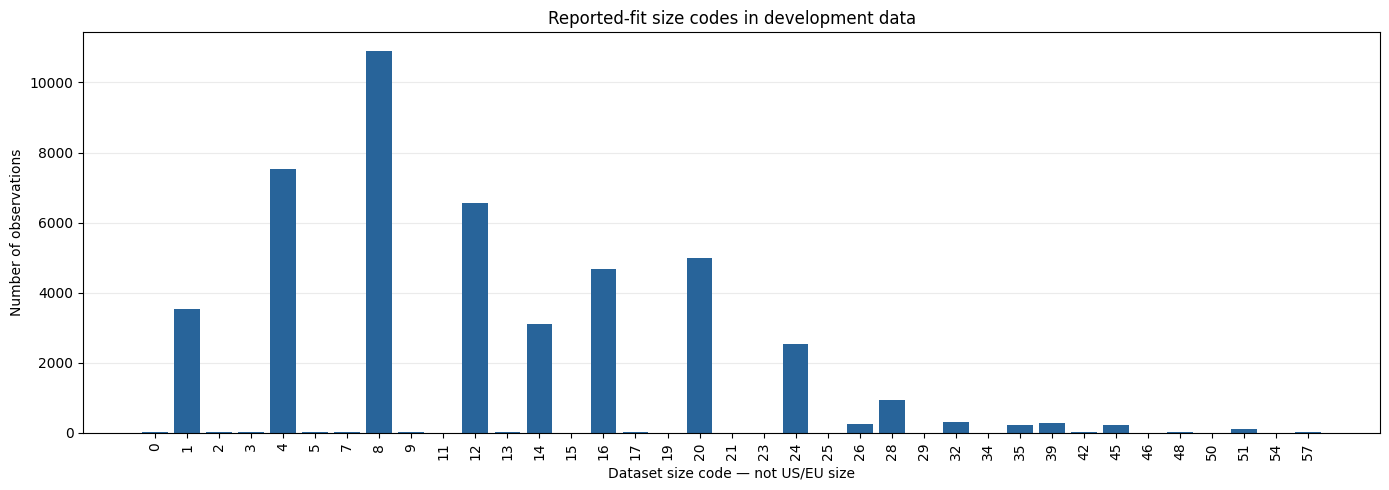

,size_code,records,percentage
0,0,15,0.03
1,1,3533,7.60
2,2,17,0.04
3,3,17,0.04
4,4,7539,16.22
5,5,32,0.07
6,7,18,0.04
7,8,10886,23.42
8,9,33,0.07
9,11,13,0.03


Model and final test results remain unchanged.


In [82]:
import matplotlib.pyplot as plt

# Count codes using development records only.
# Convert codes to text so equally spaced bars do not imply
# a physical measurement scale.
development_size_counts = (
    development_df["size_code"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    development_size_counts.index.astype(str),
    development_size_counts.values,
    color="#28649A"
)

ax.set_title("Reported-fit size codes in development data")
ax.set_xlabel("Dataset size code — not US/EU size")
ax.set_ylabel("Number of observations")
ax.tick_params(axis="x", labelrotation=90)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

# Provide exact counts alongside the chart.
size_distribution = development_size_counts.rename_axis(
    "size_code"
).reset_index(name="records")

size_distribution["percentage"] = (
    100 * size_distribution["records"] / len(development_df)
).round(2)

display(size_distribution)

print("Model and final test results remain unchanged.")

The development set contains 37 size codes with unequal frequencies.
Code 8 accounts for 23.42% of observations, followed by code 4 at 16.22%
and code 12 at 14.13%.

Several codes contain very few observations, limiting the evidence available
for learning and evaluating them. This motivates reporting per-class results
and macro F1 alongside accuracy. Rare codes were retained rather than merged
using an unverified size mapping.

### 31.2 Missing Customer Inputs

Measure missingness before imputation using development data only.
Reported bra size is a categorical input, not measured chest circumference.

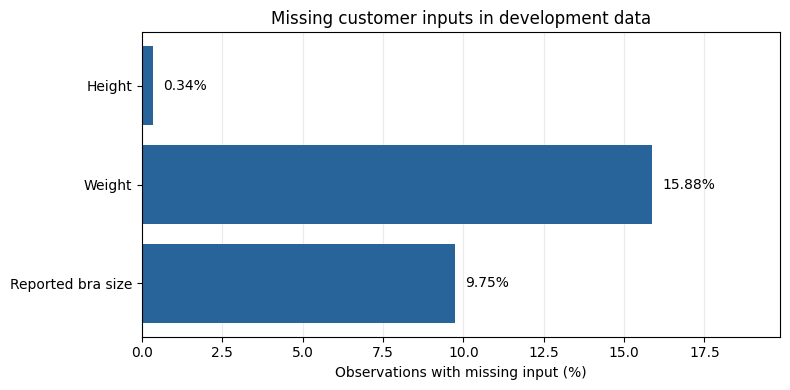

,input,missing_records,missing_percentage
0,Height,159,0.34
1,Weight,7381,15.88
2,Reported bra size,4531,9.75


In [83]:
# Calculate missingness before any model preprocessing.
missing_counts = development_df[feature_columns].isna().sum()
missing_percentages = 100 * missing_counts / len(development_df)

labels = {
    "height_cm": "Height",
    "weight_kg": "Weight",
    "bra_size": "Reported bra size"
}

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.barh(
    [labels[column] for column in feature_columns],
    missing_percentages.values,
    color="#28649A"
)

# Show exact percentages on the chart.
for bar, percentage in zip(bars, missing_percentages.values):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.2f}%",
        va="center"
    )

ax.set_title("Missing customer inputs in development data")
ax.set_xlabel("Observations with missing input (%)")
ax.set_xlim(0, max(5, missing_percentages.max() * 1.25))
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

missing_input_summary = pd.DataFrame({
    "input": [labels[column] for column in feature_columns],
    "missing_records": missing_counts.values,
    "missing_percentage": missing_percentages.round(2).values
})

display(missing_input_summary)

Weight is missing in 15.88% of development observations, reported bra size
in 9.75%, and height in 0.34%.

Incomplete observations were retained because removing them could affect
size groups unevenly. Numeric inputs were imputed using training medians,
with missingness indicators. Missing bra sizes received a separate category.

Imputation enables predictions but does not recover the true missing values.

### 31.3 Height and Weight Distributions

Inspect recorded measurements in development data before imputation.
Missing values are omitted from each histogram. Extreme values remain included.

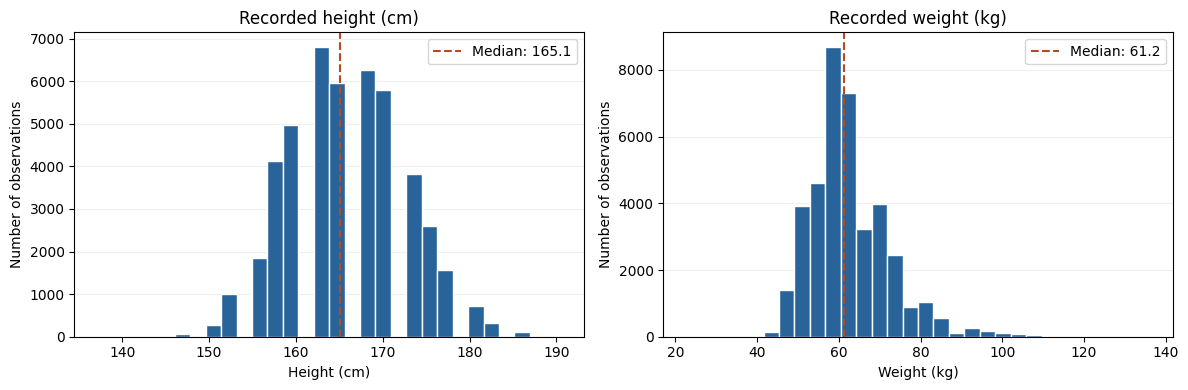

,height_cm,weight_kg
count,46318.0,39096.0
mean,165.73,62.28
std,6.75,9.82
min,137.16,22.68
1%,152.4,45.36
50%,165.1,61.23
99%,180.34,95.25
max,190.5,136.08


In [84]:
# Plot each available measurement before imputation.
# These distributions describe observations, not unique customers.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_settings = [
    ("height_cm", "Height (cm)", axes[0]),
    ("weight_kg", "Weight (kg)", axes[1])
]

for column, label, ax in plot_settings:
    values = development_df[column].dropna()

    ax.hist(
        values,
        bins=30,
        color="#28649A",
        edgecolor="white"
    )

    ax.axvline(
        values.median(),
        color="#B34A20",
        linestyle="--",
        label=f"Median: {values.median():.1f}"
    )

    ax.set_title(f"Recorded {label.lower()}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of observations")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

# Show numerical summaries alongside the distributions.
display(
    development_df[["height_cm", "weight_kg"]]
    .describe(percentiles=[0.01, 0.50, 0.99])
    .round(2)
)

The median recorded height is 165.10 cm and median weight is 61.23 kg.
The 1st and 99th percentiles are 152.40–180.34 cm for height and
45.36–95.25 kg for weight.

These summaries describe available measurements from reported-fit development
observations, rather than the general adult population. Repeated customers
may contribute multiple observations.

Extreme values remain included because the source does not establish
whether they are errors. No corrections were inferred from size codes.

### 31.4 Validation Model Comparison

Compare the initial candidate models on the same customer-grouped validation
partition. Accuracy and macro F1 show different aspects of performance.
These are validation results, not final test results.

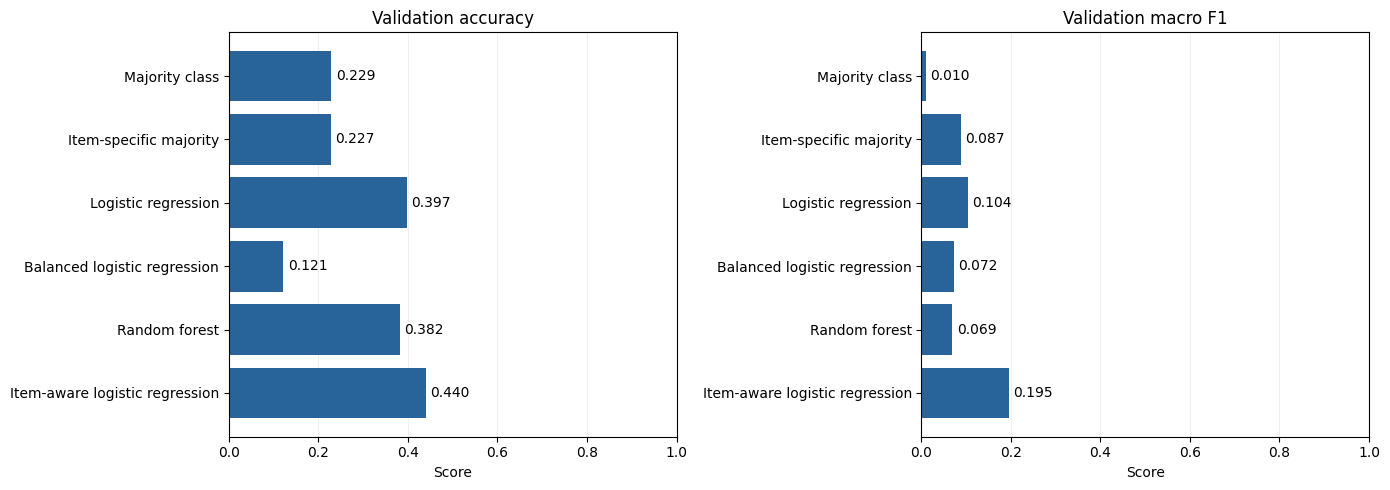

,method,validation_accuracy,macro_precision,macro_recall,macro_f1
0,Majority class,0.2290,0.0062,0.0270,0.0101
1,Item-specific majority,0.2270,0.1301,0.0808,0.0875
2,Logistic regression,0.3969,0.1428,0.0975,0.1042
3,Balanced logistic regression,0.1212,0.1128,0.1398,0.0721
4,Random forest,0.3816,0.0931,0.0721,0.0693
5,Item-aware logistic regression,0.4404,0.2380,0.1767,0.1945


In [85]:
# Assemble the previously calculated results.
# No models are retrained or changed by this cell.
validation_comparison = pd.concat(
    [
        baseline_results,
        item_baseline_results,
        logistic_results,
        balanced_results,
        forest_results,
        item_results
    ],
    ignore_index=True
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title in [
    (axes[0], "validation_accuracy", "Validation accuracy"),
    (axes[1], "macro_f1", "Validation macro F1")
]:
    bars = ax.barh(
        validation_comparison["method"],
        validation_comparison[metric],
        color="#28649A"
    )

    for bar, value in zip(bars, validation_comparison[metric]):
        ax.text(
            value + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center"
        )

    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Score")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

display(validation_comparison.round(4))

Among the initial candidates, item-aware logistic regression achieved the
highest validation accuracy (44.04%) and macro F1 (0.1945).
Including dress identity improved accuracy over customer-only logistic
regression by 4.35 percentage points.

In the subsequent regularisation comparison, C = 10 achieved higher macro F1,
but C = 1 was selected under the predefined accuracy-first rule.

The statistical baselines do not substitute for a traditional size chart.

### 31.5 Final Test Confusion Matrix

Display all 37 size codes using the fixed evaluation label list.
Each row shows the percentage of observations predicted as each code.

Diagonal cells represent correct predictions. Classes without test observations
are marked as unavailable, rather than interpreted as measured zero recall.
This analysis does not change the model.

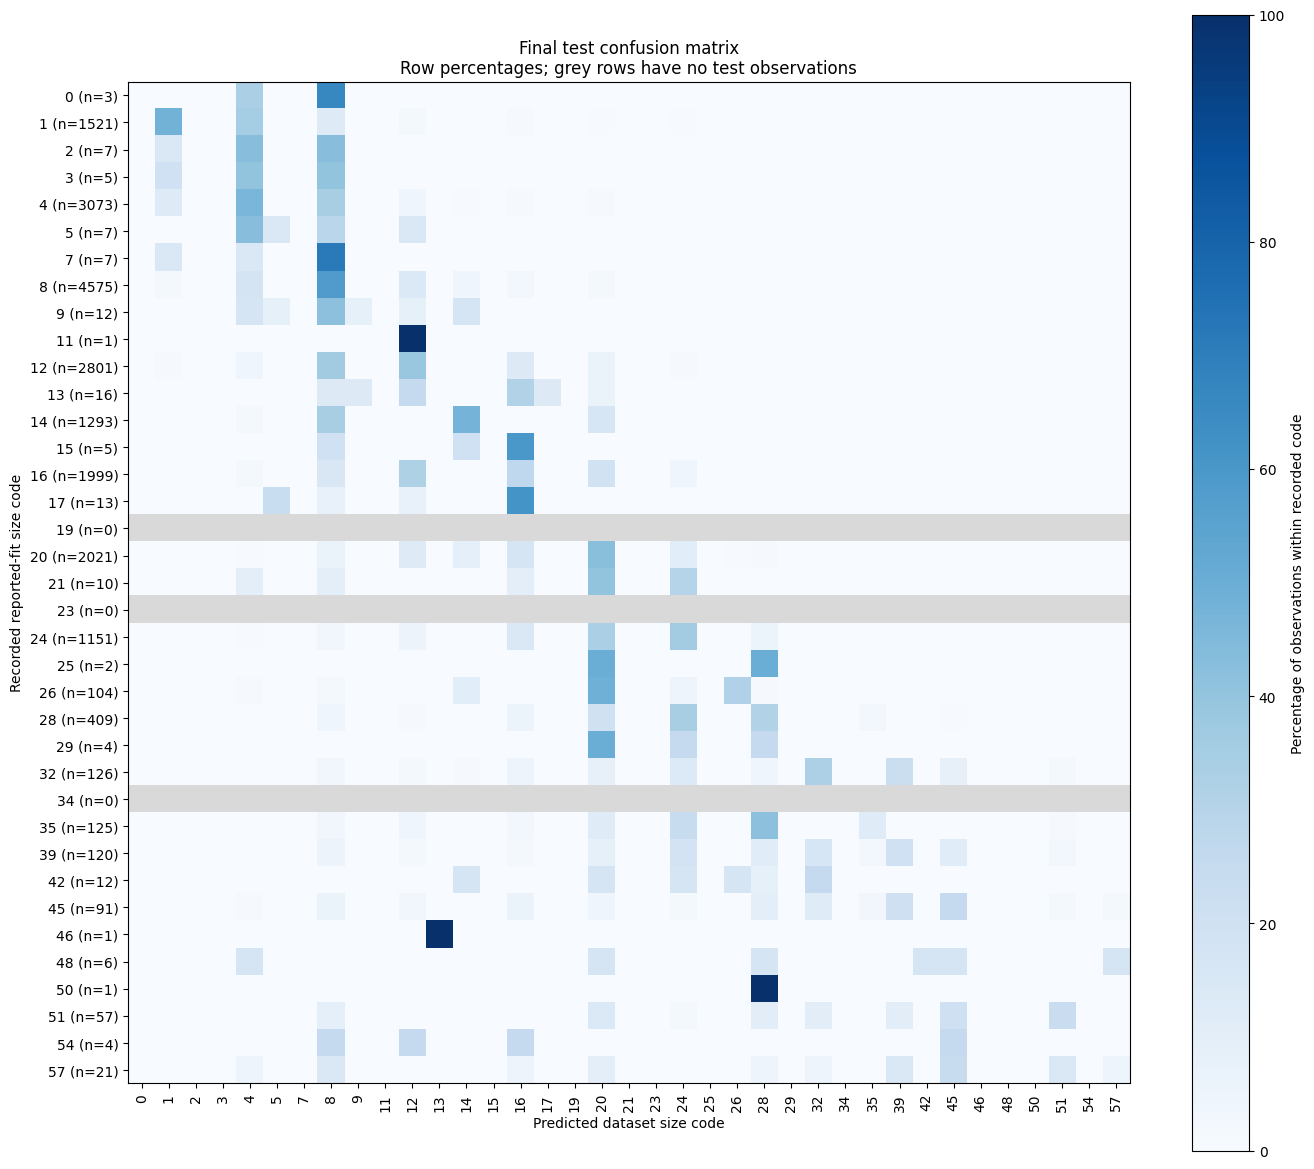

Test observations represented: 19603
Codes without test observations: [np.int64(19), np.int64(23), np.int64(34)]
Model and settings remain unchanged.


In [86]:
from sklearn.metrics import confusion_matrix

# Use existing final predictions; do not retrain the model.
test_confusion_counts = confusion_matrix(
    y_test,
    final_predictions,
    labels=evaluation_labels
)

row_totals = test_confusion_counts.sum(axis=1)

# Normalise each row to percentages.
# Rows without observations remain unavailable (NaN).
test_confusion_percent = np.full(
    test_confusion_counts.shape,
    np.nan,
    dtype=float
)

np.divide(
    test_confusion_counts * 100.0,
    row_totals[:, None],
    out=test_confusion_percent,
    where=row_totals[:, None] != 0
)

# Grey indicates a size code with no test observations.
colour_map = plt.get_cmap("Blues").copy()
colour_map.set_bad("#D9D9D9")

fig, ax = plt.subplots(figsize=(14, 12))

heatmap = ax.imshow(
    np.ma.masked_invalid(test_confusion_percent),
    cmap=colour_map,
    vmin=0,
    vmax=100,
    interpolation="nearest"
)

positions = np.arange(len(evaluation_labels))

ax.set_xticks(positions)
ax.set_xticklabels(evaluation_labels, rotation=90)

# Include sample counts because percentages for rare codes are unstable.
ax.set_yticks(positions)
ax.set_yticklabels([
    f"{code} (n={count})"
    for code, count in zip(evaluation_labels, row_totals)
])

ax.set_xlabel("Predicted dataset size code")
ax.set_ylabel("Recorded reported-fit size code")
ax.set_title(
    "Final test confusion matrix\n"
    "Row percentages; grey rows have no test observations"
)

fig.colorbar(
    heatmap,
    ax=ax,
    label="Percentage of observations within recorded code"
)

fig.tight_layout()
plt.show()

print("Test observations represented:", int(row_totals.sum()))
print(
    "Codes without test observations:",
    [
        code
        for code, count in zip(evaluation_labels, row_totals)
        if count == 0
    ]
)
print("Model and settings remain unchanged.")

The confusion matrix shows uneven performance across size codes.
For example, code 8 has 57.88% recall, while code 57 has 4.76% recall
from only 21 test observations.

Codes 19, 23 and 34 have no test observations and cannot be assessed.
Small sample counts make several other class-level estimates uncertain.

Off-diagonal cells represent disagreement with the recorded fitting code.
They do not prove that the predicted size would fail to fit, because outcomes
for alternative sizes are generally unobserved. Code differences must not
be interpreted as centimetres or verified US/EU size steps.